# Soluções candidatas para maior `salary_usd` no recorte BRL

Um ciclo do laço de `ciclos_otimizacao.png`: **DAMICORE → modelo probabilístico → soluções candidatas → solução escolhida**, aplicado só às linhas de `my_datasets/main_ai_ds_job_salaries_2026.csv` com `salary_currency == "BRL"`.

- O DAMICORE é rodado de novo nesse recorte; os clusters de colunas vêm do resultado, não dos 7 clusters do quartil.
- Seleção: as 25% mais bem pagas das 210 linhas (coluna `top`).
- Só colunas acionáveis entram na solução; ficam fora as de consequência e as que são constantes no recorte.
- Tudo é gravado em `my_datasets/salary_brl/`. Rode a partir da raiz do repositório, no ambiente `dami`.

In [1]:
from itertools import product
from pathlib import Path

import pandas as pd

data_dir = Path("my_datasets")
brl_dir = data_dir / "salary_brl"
results_dir = brl_dir / "damicore_results"
out_dir = brl_dir / "report"
out_dir.mkdir(parents=True, exist_ok=True)
dataset_path = brl_dir / "salary_dataset_brl_main.csv"
target = "salary_usd"

source = pd.read_csv(data_dir / "main_ai_ds_job_salaries_2026.csv")
main = source[source["salary_currency"] == "BRL"].reset_index(drop=True)
main.to_csv(dataset_path, index=False)
print(f"{len(main)} linhas com salary_currency = BRL (de {len(source)}) gravadas em {dataset_path}")

210 linhas com salary_currency = BRL (de 5000) gravadas em my_datasets/salary_brl/salary_dataset_brl_main.csv


## DAMICORE no recorte

Agrupa as 27 colunas. O resultado fica em `my_datasets/salary_brl/damicore_results/`; se a pasta já tiver um resultado, ele é reaproveitado. Cada cluster ganha um CSV e a sua tabela de probabilidade (`_prob.csv`).

In [2]:
from damicore import run

# DAMICORE never overwrites a saved run, so it only runs when there is no result yet.
if not (results_dir / "membership.csv").exists():
    result = run(dataset_path, split="columns", progress=False)
    result.save(str(results_dir))
    result.close()

membership = pd.read_csv(results_dir / "membership.csv").set_index("object_id")
cluster_columns = {int(c): list(group["label"]) for c, group in membership.groupby("cluster")}
assert sorted(sum(cluster_columns.values(), [])) == sorted(main.columns)

# One file per cluster plus its probability table: frequency of each distinct row over all rows.
for cluster, cols in cluster_columns.items():
    main[cols].to_csv(brl_dir / f"salary_dataset_brl_cluster{cluster}.csv", index=False)
    prob = main.groupby(cols).size().div(len(main)).rename("prob_set").reset_index()
    assert abs(prob["prob_set"].sum() - 1) < 1e-9
    prob.sort_values("prob_set", ascending=False).to_csv(
        brl_dir / f"salary_dataset_brl_cluster{cluster}_prob.csv", index=False
    )
    print(f"cluster {cluster}: {', '.join(cols)}  ({len(prob)} linhas distintas)")

cluster 0: job_title, experience_level, industry, education_level, primary_language  (202 linhas distintas)
cluster 1: employment_type, company_location, employee_residence, salary_currency  (16 linhas distintas)
cluster 2: company_size, remote_ratio, salary_usd, equity_offered_pct  (210 linhas distintas)
cluster 3: years_experience, ai_tools_hours_per_week, bonus_pct, upskilling_hours_per_month  (210 linhas distintas)
cluster 4: has_ml_in_title, manages_people, uses_ai_tools_daily, switched_jobs_last_year  (15 linhas distintas)
cluster 5: team_size, certifications_count, interviews_to_offer  (155 linhas distintas)
cluster 6: weekly_hours, job_satisfaction_score, fears_ai_automation_score  (210 linhas distintas)


/home/lobo/miniconda3/envs/dami/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


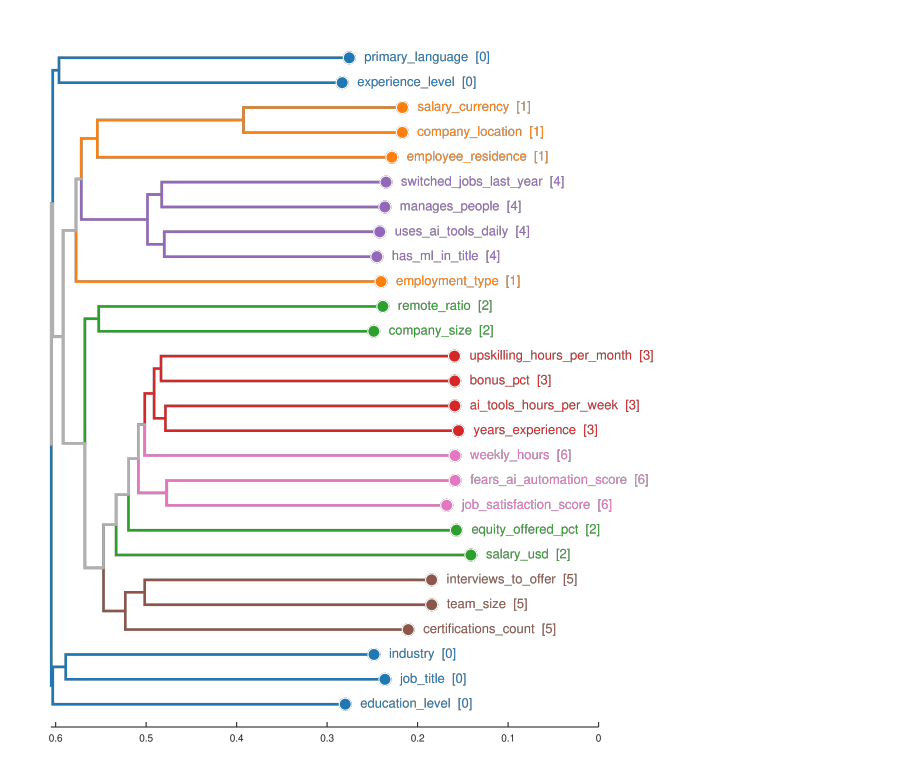

In [3]:
import toyplot.pdf
import toytree

tree = toytree.tree((results_dir / "tree.nwk").read_text())

# toytree keeps the Newick quotes in node names; drop them so names match the object ids.
for node in tree:
    node.name = node.name.strip("'")

# One color per cluster; an edge takes a cluster's color only when every leaf below it belongs to
# that cluster.
palette = [
    "#1f77b4",
    "#ff7f0e",
    "#2ca02c",
    "#d62728",
    "#9467bd",
    "#8c564b",
    "#e377c2",
    "#17becf",
    "#bcbd22",
    "#7f7f7f",
]
cluster_color = {
    c: palette[i % len(palette)] for i, c in enumerate(sorted(membership["cluster"].unique()))
}
mixed_color = "#b0b0b0"


def node_color(node: toytree.Node) -> str:
    clusters = {membership.at[name, "cluster"] for name in node.get_leaf_names()}
    return cluster_color[clusters.pop()] if len(clusters) == 1 else mixed_color


tips = [tree[i] for i in range(tree.ntips)]
tree_canvas, _, _ = tree.draw(
    layout="r",
    width=900,
    height=26 * tree.ntips + 60,
    tip_labels=[
        f"{membership.at[t.name, 'label']}  [{membership.at[t.name, 'cluster']}]" for t in tips
    ],
    tip_labels_colors=[node_color(t) for t in tips],
    tip_labels_style={"font-size": "13px"},
    edge_colors=[node_color(tree[i]) for i in range(tree.nnodes)],
    edge_widths=2.5,
    node_mask=False,
    node_sizes=[12 if tree[i].is_leaf() else 0 for i in range(tree.nnodes)],
    node_colors=[node_color(tree[i]) for i in range(tree.nnodes)],
    node_style={"stroke": "white", "stroke-width": 1},
    scale_bar=True,
)
toyplot.pdf.render(tree_canvas, str(results_dir / "tree_colored.pdf"))
tree_canvas

## Seleção e variáveis de decisão

In [4]:
# Columns that describe an outcome (or the objective itself) stay out of a solution.
not_actionable = {
    "salary_usd",
    "bonus_pct",
    "equity_offered_pct",
    "interviews_to_offer",
    "job_satisfaction_score",
    "fears_ai_automation_score",
}
# A column with a single value in this dataset leaves nothing to choose.
constant = {name for name in main.columns if main[name].nunique() == 1}
numeric_actionable = [
    "years_experience",
    "ai_tools_hours_per_week",
    "upskilling_hours_per_month",
    "team_size",
    "certifications_count",
    "weekly_hours",
]
shrinkage = 20  # weight, in rows, of the independent-columns estimate
min_value_rows = 15  # a value needs this many rows before it can enter a solution
blocks_per_cluster = 3

# Selection step of the cycle: the best-paid quarter of the 210 rows.
selected_fraction = 0.25
threshold = main[target].quantile(1 - selected_fraction)
main["top"] = main[target] >= threshold
base_rate = main["top"].mean()
base_odds = base_rate / (1 - base_rate)

decision = {
    c: [n for n in cols if n not in not_actionable | constant]
    for c, cols in cluster_columns.items()
}
skipped = [c for c, cols in decision.items() if not cols]
decision = {c: cols for c, cols in decision.items() if cols}
print(f"{len(main)} linhas, {int(main['top'].sum())} selecionadas (salary_usd >= {threshold:,.0f})")
print(f"colunas constantes: {sorted(constant)}; clusters sem coluna acionável: {skipped}")
decision

210 linhas, 53 selecionadas (salary_usd >= 47,431)
colunas constantes: ['company_location', 'salary_currency']; clusters sem coluna acionável: []


{0: ['job_title',
  'experience_level',
  'industry',
  'education_level',
  'primary_language'],
 1: ['employment_type', 'employee_residence'],
 2: ['company_size', 'remote_ratio'],
 3: ['years_experience',
  'ai_tools_hours_per_week',
  'upskilling_hours_per_month'],
 4: ['has_ml_in_title',
  'manages_people',
  'uses_ai_tools_daily',
  'switched_jobs_last_year'],
 5: ['team_size', 'certifications_count'],
 6: ['weekly_hours']}

## Modelo probabilístico por cluster

Para cada cluster, duas tabelas com a mesma regra (frequência do bloco ÷ total de linhas): `p_bloco_topo` nas linhas selecionadas e `p_bloco` nas 210. Por Bayes, `P(selecionada | bloco) = 0,25 · p_bloco_topo / p_bloco`.

Como a amostra é pequena, blocos com poucas linhas são puxados para a estimativa por colunas independentes dentro do cluster (`p_indep`), com peso de 20 linhas, e um valor só pode entrar na solução se aparecer em pelo menos 15 linhas (`elegivel`). As colunas numéricas viram três faixas com cortes do próprio recorte.

In [5]:
def to_bands(column: pd.Series) -> pd.Series:
    """Split a numeric column into three bands using cuts from the whole dataset."""
    low, high = column.quantile([1 / 3, 2 / 3])
    labels = {
        0: f"baixo (até {low:.3g})",
        1: f"médio ({low:.3g} a {high:.3g})",
        2: f"alto (acima de {high:.3g})",
    }
    return ((column > low).astype(int) + (column > high).astype(int)).map(labels)


model = main.copy()
for name in numeric_actionable:
    model[name] = to_bands(main[name])
for cols in decision.values():
    for name in cols:
        model[name] = model[name].astype(str)


def odds(p):
    return p / (1 - p)


def cluster_table(cluster: int) -> pd.DataFrame:
    cols = decision[cluster]
    table = (
        model.groupby(cols)
        .agg(
            n=("top", "size"),
            n_top=("top", "sum"),
            salario_mediano=(target, "median"),
            salario_maximo=(target, "max"),
        )
        .reset_index()
    )
    table["p_bloco"] = table["n"] / len(model)
    table["p_bloco_topo"] = table["n_top"] / model["top"].sum()
    table["p_topo_bruto"] = table["n_top"] / table["n"]
    # Independent-columns estimate inside the cluster: product of each column's odds ratio.
    ratio = pd.Series(1.0, index=table.index)
    table["elegivel"] = True
    for name in cols:
        by_value = model.groupby(name)["top"].agg(["size", "sum"])
        table["elegivel"] &= table[name].map(by_value["size"] >= min_value_rows)
        p_value = (by_value["sum"] + base_rate) / (by_value["size"] + 1)
        ratio *= table[name].map(odds(p_value) / base_odds)
    table["p_indep"] = base_odds * ratio / (1 + base_odds * ratio)
    # Rare blocks lean on the independent estimate; well-supported blocks keep their own frequency.
    table["p_topo"] = (table["n_top"] + shrinkage * table["p_indep"]) / (table["n"] + shrinkage)
    table["razao_chance"] = odds(table["p_topo"]) / base_odds
    table.insert(0, "cluster", cluster)
    return table.sort_values("p_topo", ascending=False, ignore_index=True)


tables = {c: cluster_table(c) for c in decision}
for t in tables.values():
    assert abs(t["p_bloco"].sum() - 1) < 1e-9 and abs(t["p_bloco_topo"].sum() - 1) < 1e-9
    assert abs((t["p_topo_bruto"] * t["p_bloco"]).sum() - base_rate) < 1e-9

# Blocks built on a value with too few rows are kept in the table but cannot be chosen.
best = {c: t[t["elegivel"]].head(blocks_per_cluster) for c, t in tables.items()}
for c, t in best.items():
    print(
        f"cluster {c}: {len(tables[c])} blocos distintos, {int(tables[c]['elegivel'].sum())} "
        f"elegíveis"
    )
    display(
        t[
            decision[c]
            + [
                "n",
                "n_top",
                "p_bloco_topo",
                "p_bloco",
                "p_topo",
                "salario_mediano",
                "salario_maximo",
            ]
        ]
    )

cluster 0: 202 blocos distintos, 74 elegíveis


,job_title,experience_level,industry,education_level,primary_language,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
11,Machine Learning Engineer,Lead,Technology,Masters,Python,1,1,0.018868,0.004762,0.751426,73552.0,73552
12,Data Engineer,Lead,Technology,Masters,Python,2,2,0.037736,0.009524,0.726282,64926.5,80070
15,Research Scientist,Senior,Healthcare,Masters,SQL,1,1,0.018868,0.004762,0.665893,54338.0,54338


cluster 1: 16 blocos distintos, 2 elegíveis


,employment_type,employee_residence,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
9,Full-time,BR,155,38,0.716981,0.738095,0.244164,36551.0,80070
10,Contract,BR,14,2,0.037736,0.066667,0.180247,32858.5,69717


cluster 2: 9 blocos distintos, 9 elegíveis


...

,has_ml_in_title,manages_people,uses_ai_tools_daily,switched_jobs_last_year,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
0,True,True,True,False,8,8,0.150943,0.038095,0.808920,61688.5,83582
1,True,True,True,True,4,4,0.075472,0.019048,0.725808,64385.0,73552
2,False,True,True,False,17,9,0.169811,0.080952,0.536557,50070.0,80070


cluster 5: 9 blocos distintos, 9 elegíveis


,team_size,certifications_count,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
0,baixo (até 7),alto (acima de 2),19,8,0.150943,0.090476,0.361462,41872.0,69717
1,médio (7 a 9),alto (acima de 2),20,6,0.113208,0.095238,0.340775,37822.0,83582
2,alto (acima de 9),alto (acima de 2),14,4,0.075472,0.066667,0.321668,41916.0,58343


cluster 6: 3 blocos distintos, 3 elegíveis


,weekly_hours,n,n_top,p_bloco_topo,p_bloco,p_topo,salario_mediano,salario_maximo
0,alto (acima de 46.3),70,23,0.433962,0.333333,0.328333,37317.5,83582
1,médio (41.8 a 46.3),70,18,0.339623,0.333333,0.257128,38035.5,80070
2,baixo (até 41.8),70,12,0.226415,0.333333,0.171682,32415.5,72920


## Soluções candidatas

Combinações dos 3 melhores blocos elegíveis de cada cluster. A pontuação é o produto das razões de chance dos blocos e serve só para ordenar: os clusters são tratados como independentes entre si, então ela não é uma probabilidade.

In [6]:
def describe(cluster: int, row: pd.Series) -> str:
    return "; ".join(f"{name}={row[name]}" for name in decision[cluster])


records = []
for choice in product(*(range(len(best[c])) for c in decision)):
    rows = {c: best[c].iloc[i] for c, i in zip(decision, choice)}
    score = 1.0
    for row in rows.values():
        score *= row["razao_chance"]
    record = {"pontuacao": score}
    record.update({f"posicao_{c}": i + 1 for c, i in zip(decision, choice)})
    record.update({f"bloco_{c}": describe(c, row) for c, row in rows.items()})
    records.append(record)
candidates = pd.DataFrame(records).sort_values("pontuacao", ascending=False, ignore_index=True)
candidates.insert(0, "candidata", candidates.index + 1)
candidates.insert(
    2, "pontuacao_relativa", candidates["pontuacao"] / candidates["pontuacao"].iloc[0]
)

print(f"{len(candidates)} candidatas")
candidates.head(10)[["candidata", "pontuacao_relativa"] + [f"posicao_{c}" for c in decision]]

1458 candidatas


,candidata,pontuacao_relativa,posicao_0,posicao_1,posicao_2,posicao_3,posicao_4,posicao_5,posicao_6
0,1,1.000000,1,1,1,1,1,1,1
1,2,0.913184,1,1,1,1,1,2,1
2,3,0.877753,2,1,1,1,1,1,1
3,4,0.837703,1,1,1,1,1,3,1
4,5,0.820353,1,1,2,1,1,1,1
5,6,0.801550,2,1,1,1,1,2,1
6,7,0.772154,1,1,1,2,1,1,1
7,8,0.749134,1,1,2,1,1,2,1
8,9,0.738043,1,1,3,1,1,1,1
9,10,0.735296,2,1,1,1,1,3,1


## Solução escolhida

A candidata de maior pontuação, aberta coluna a coluna. `p_topo` é a parcela das linhas com aquele valor que está entre as selecionadas (a base é 25%) e `p_topo_demais` é a mesma parcela nas outras linhas.

`peso` é **forte** quando a coluna separa bem (mais de 15 pontos entre o melhor e o pior valor) e o valor escolhido supera as demais linhas por pelo menos 2 erros-padrão (`z`); **quase nenhum** quando a coluna separa até 5 pontos; **moderado** no resto. O teste de `z` existe porque, com 210 linhas, diferenças de 15 pontos aparecem por acaso.

In [7]:
chosen = {c: best[c].iloc[0] for c in decision}
strong_z = 2.0  # the chosen value must beat the remaining rows by this many standard errors

# Effect of each column alone: shows which parts of the chosen blocks actually carry weight.
effects = []
for c in decision:
    for name in decision[c]:
        by_value = model.groupby(name).agg(
            n=("top", "size"),
            n_top=("top", "sum"),
            p_topo=("top", "mean"),
            mediana=(target, "median"),
            maximo=(target, "max"),
        )
        solid = by_value[by_value["n"] >= min_value_rows]
        value = chosen[c][name]
        n, n_top = int(by_value.at[value, "n"]), int(by_value.at[value, "n_top"])
        # Two-proportion z: rows with the chosen value against all the other rows.
        rest, rest_top = len(model) - n, int(model["top"].sum()) - n_top
        spread = (base_rate * (1 - base_rate) * (1 / n + 1 / rest)) ** 0.5 if rest else float("inf")
        effects.append(
            {
                "cluster": c,
                "coluna": name,
                "valor_escolhido": value,
                "linhas": n,
                "linhas_selecionadas": n_top,
                "p_topo": n_top / n,
                "p_topo_demais": rest_top / rest if rest else float("nan"),
                "z": (n_top / n - rest_top / rest) / spread if rest else 0.0,
                "salario_mediano": by_value.at[value, "mediana"],
                "salario_maximo": by_value.at[value, "maximo"],
                "melhor_valor": solid["p_topo"].idxmax(),
                "p_topo_melhor": solid["p_topo"].max(),
                "p_topo_pior": solid["p_topo"].min(),
            }
        )
solution = pd.DataFrame(effects)
solution["amplitude"] = solution["p_topo_melhor"] - solution["p_topo_pior"]
solution["peso"] = "moderado"
solution.loc[(solution["amplitude"] > 0.15) & (solution["z"] >= strong_z), "peso"] = "forte"
solution.loc[solution["amplitude"] <= 0.05, "peso"] = "quase nenhum"
solution

,cluster,coluna,valor_escolhido,linhas,linhas_selecionadas,p_topo,p_topo_demais,z,salario_mediano,salario_maximo,melhor_valor,p_topo_melhor,p_topo_pior,amplitude,peso
0,0,job_title,Machine Learning Engineer,31,9,0.290323,0.245810,0.526758,37821.0,83582,Research Scientist,0.500000,0.000000,0.500000,moderado
1,0,experience_level,Lead,27,15,0.555556,0.207650,3.884994,53265.0,83582,Lead,0.555556,0.000000,0.555556,forte
2,0,industry,Technology,57,17,0.298246,0.235294,0.933923,38169.0,80070,Healthcare,0.333333,0.235294,0.098039,moderado
3,0,education_level,Masters,81,26,0.320988,0.209302,1.813658,37823.0,83582,Masters,0.320988,0.100000,0.220988,moderado
4,0,primary_language,Python,120,33,0.275000,0.222222,0.871334,37914.0,80070,Python,0.275000,0.196078,0.078922,moderado
5,1,employment_type,Full-time,180,46,0.255556,0.233333,0.259422,37098.0,83582,Full-time,0.255556,0.222222,0.033333,quase nenhum
6,1,employee_residence,BR,180,42,0.233333,0.366667,-1.556530,35793.0,80070,BR,0.233333,0.233333,0.000000,quase nenhum
7,2,company_size,L,32,13,0.406250,0.224719,2.176494,42443.0,64618,L,0.406250,0.142857,0.263393,forte
8,2,remote_ratio,50,58,15,0.258621,0.250000,0.128588,34141.5,71730,50,0.258621,0.250000,0.008621,quase nenhum
9,3,years_experience,alto (acima de 9.8),69,35,0.507246,0.127660,5.947947,47463.0,83582,alto (acima de 9.8),0.507246,0.014286,0.492961,forte


## Conferência com linhas reais

Todo valor em dólar abaixo é mediana de linhas reais do recorte, agrupadas por quanto se parecem com a solução.

In [8]:
def summarize(groups: pd.Series, name: str) -> pd.DataFrame:
    return (
        main.groupby(groups, observed=True)
        .agg(
            linhas=(target, "size"),
            salario_mediano=(target, "median"),
            salario_maximo=(target, "max"),
            no_topo=("top", "mean"),
        )
        .reset_index(names=name)
    )


# Whole blocks: how many of the chosen blocks each real row matches.
block_hits = pd.DataFrame(
    {c: (model[decision[c]] == chosen[c][decision[c]].values).all(axis=1) for c in decision}
)
block_check = summarize(block_hits.sum(axis=1), "blocos_casados")

# Strong columns only: how many of them each real row matches.
strong = solution[solution["peso"] == "forte"]
strong_hits = pd.DataFrame(
    {r.coluna: model[r.coluna] == r.valor_escolhido for r in strong.itertuples()}
)
strong_count = strong_hits.sum(axis=1)
# Merge the sparse ends so that every group has at least min_value_rows rows.
low = min(v for v in range(len(strong) + 1) if (strong_count <= v).sum() >= min_value_rows)
high = max(v for v in range(len(strong) + 1) if (strong_count >= v).sum() >= min_value_rows)
labels = {v: str(v) for v in range(low, high + 1)}
labels[low], labels[high] = (
    f"0 a {low}" if low else "0",
    f"{high} a {len(strong)}" if high < len(strong) else str(high),
)
strong_check = summarize(strong_count.clip(low, high), "colunas_fortes_casadas")
strong_check["colunas_fortes_casadas"] = strong_check["colunas_fortes_casadas"].map(labels)

display(block_check)
display(strong_check)

,blocos_casados,linhas,salario_mediano,salario_maximo,no_topo
0,0,30,27204.5,58343,0.133333
1,1,108,35922.5,80070,0.212963
2,2,63,37077.0,74785,0.269841
3,3,9,60994.0,83582,1.000000


,colunas_fortes_casadas,linhas,salario_mediano,salario_maximo,no_topo
0,0,30,29301.0,50435,0.066667
1,1,59,29531.0,48600,0.016949
2,2,66,38804.5,71730,0.318182
3,3,28,43456.5,74785,0.357143
4,4 a 6,27,55589.0,83582,0.703704


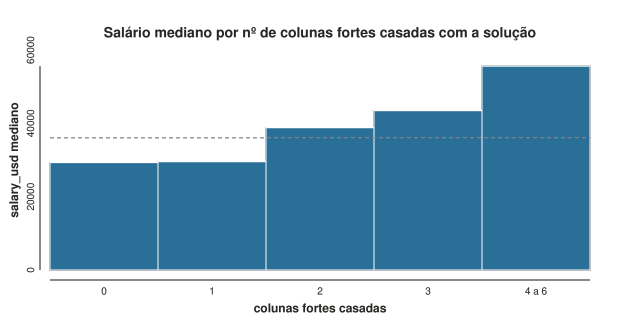

In [9]:
import toyplot

canvas = toyplot.Canvas(width=640, height=320)
axes = canvas.cartesian(
    label="Salário mediano por nº de colunas fortes casadas com a solução",
    xlabel="colunas fortes casadas",
    ylabel="salary_usd mediano",
)
axes.bars(strong_check["salario_mediano"].to_numpy(), color="#2a6f97")
axes.x.ticks.locator = toyplot.locator.Explicit(
    labels=list(strong_check["colunas_fortes_casadas"].astype(str))
)
axes.hlines(main[target].median(), style={"stroke": "#888", "stroke-dasharray": "4,3"})
canvas

## Arquivos do report

Grava os CSVs e o `report.pdf` em `my_datasets/salary_brl/report/`. A última tabela mostra valores que ficaram fora por terem poucas linhas.

In [10]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import mm
from reportlab.platypus import Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

# Values left out for having too few rows, with what the few rows show (context for the report).
left_out = pd.concat(
    model.groupby(name)
    .agg(
        linhas=("top", "size"),
        p_topo=("top", "mean"),
        salario_mediano=(target, "median"),
        salario_maximo=(target, "max"),
    )
    .query("linhas < @min_value_rows")
    .rename_axis("valor")
    .reset_index()
    .assign(coluna=name)
    for cols in decision.values()
    for name in cols
)[["coluna", "valor", "linhas", "p_topo", "salario_mediano", "salario_maximo"]]

pd.concat(tables.values()).to_csv(out_dir / "blocos_por_cluster.csv", index=False)
candidates.to_csv(out_dir / "solucoes_candidatas.csv", index=False)
solution.to_csv(out_dir / "solucao_escolhida.csv", index=False)
strong_check.to_csv(out_dir / "conferencia_colunas_fortes.csv", index=False)
block_check.to_csv(out_dir / "conferencia_blocos.csv", index=False)
left_out.to_csv(out_dir / "valores_fora_por_poucas_linhas.csv", index=False)

styles = getSampleStyleSheet()
body, small = styles["BodyText"], styles["BodyText"].clone("small", fontSize=8, leading=10)


def money(value: float) -> str:
    return f"US$ {value:,.0f}".replace(",", ".")


def pct(value: float) -> str:
    return f"{value:.0%}"


def pdf_table(rows: list[list[str]], widths: list[float]) -> Table:
    table = Table(
        [[Paragraph(str(cell), small) for cell in row] for row in rows],
        colWidths=[w * mm for w in widths],
        repeatRows=1,
    )
    table.setStyle(
        TableStyle(
            [
                ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#e6eef3")),
                ("LINEBELOW", (0, 0), (-1, -1), 0.3, colors.HexColor("#b8c4cc")),
                ("VALIGN", (0, 0), (-1, -1), "TOP"),
            ]
        )
    )
    return table


top_group = strong_check.iloc[-1]
strong_names = ", ".join(strong["coluna"])
# The left-out value whose few rows look best: the report names it so the floor does not hide it.
notable = left_out[left_out["linhas"] >= 5].nlargest(1, "p_topo").iloc[0]
thin_blocks = ", ".join(
    f"cluster {c} ({int(row['n'])})" for c, row in chosen.items() if row["n"] < min_value_rows
)
story = [
    Paragraph("Solução escolhida para maior salary_usd no recorte BRL", styles["Title"]),
    Paragraph(
        f"Ciclo aplicado uma vez: DAMICORE rodado no recorte ({len(cluster_columns)} clusters de "
        f"colunas) → modelo probabilístico "
        f"por cluster → {len(candidates)} soluções candidatas → solução escolhida. Base: as "
        f"{len(main)} linhas com "
        f"salary_currency = BRL. Seleção: as {int(main['top'].sum())} mais bem pagas (salary_usd a "
        f"partir de {money(threshold)}).",
        body,
    ),
    Spacer(1, 2.5 * mm),
    Paragraph(
        f"Nas linhas reais que casam com {top_group['colunas_fortes_casadas']} das {len(strong)} "
        f"colunas de peso forte "
        f"da solução, o salário mediano é {money(top_group['salario_mediano'])} e "
        f"{pct(top_group['no_topo'])} estão entre "
        f"as selecionadas ({int(top_group['linhas'])} linhas); o maior salário desse grupo é "
        f"{money(top_group['salario_maximo'])}. "
        f"No recorte inteiro, o maior salary_usd é {money(main[target].max())} e a mediana é "
        f"{money(main[target].median())}.",
        body,
    ),
    Spacer(1, 2.5 * mm),
    Paragraph("Clusters do DAMICORE no recorte", styles["Heading2"]),
    pdf_table(
        [["Cluster", "Colunas", "Entram na solução"]]
        + [
            [c, ", ".join(cols), ", ".join(decision.get(c, [])) or "nenhuma"]
            for c, cols in cluster_columns.items()
        ],
        [14, 85, 85],
    ),
    Spacer(1, 2.5 * mm),
    Paragraph("Solução escolhida, coluna a coluna", styles["Heading2"]),
    Paragraph(
        "Selec. = linhas com o valor que estão entre as selecionadas / linhas com o valor. Dem. = "
        "a mesma parcela nas outras linhas.",
        small,
    ),
    pdf_table(
        [["Cl.", "Coluna", "Valor escolhido", "Selec.", "Dem.", "Mediana", "Máximo", "Peso"]]
        + [
            [
                r.cluster,
                r.coluna,
                r.valor_escolhido,
                f"{r.linhas_selecionadas}/{r.linhas} ({pct(r.p_topo)})",
                pct(r.p_topo_demais),
                money(r.salario_mediano),
                money(r.salario_maximo),
                r.peso,
            ]
            for r in solution.itertuples()
        ],
        [9, 43, 34, 24, 11, 21, 21, 17],
    ),
    Spacer(1, 2.5 * mm),
    Paragraph("Conferência com linhas reais", styles["Heading2"]),
    Paragraph(f"Colunas de peso forte: {strong_names}.", small),
    pdf_table(
        [
            [
                "Colunas fortes casadas",
                "Linhas",
                "Salário mediano",
                "Maior salário",
                "Entre as selecionadas",
            ]
        ]
        + [
            [
                r.colunas_fortes_casadas,
                r.linhas,
                money(r.salario_mediano),
                money(r.salario_maximo),
                pct(r.no_topo),
            ]
            for r in strong_check.itertuples()
        ],
        [40, 20, 35, 35, 40],
    ),
    Spacer(1, 2.5 * mm),
    Paragraph("Melhor bloco de cada cluster", styles["Heading2"]),
    pdf_table(
        [["Cl.", "Bloco", "Linhas", "Selec. (bruto)", "Estim.", "Mediana", "Máximo"]]
        + [
            [
                c,
                describe(c, row),
                int(row["n"]),
                pct(row["p_topo_bruto"]),
                pct(row["p_topo"]),
                money(row["salario_mediano"]),
                money(row["salario_maximo"]),
            ]
            for c, row in chosen.items()
        ],
        [12, 76, 13, 20, 17, 21, 21],
    ),
    Spacer(1, 2.5 * mm),
    Paragraph("As 10 melhores candidatas", styles["Heading2"]),
    Paragraph(
        "Posição do bloco usado em cada cluster (1 = melhor bloco do cluster). Pontuação relativa "
        "à escolhida.",
        small,
    ),
    pdf_table(
        [["Candidata", "Pontuação"] + [f"C{c}" for c in decision]]
        + [
            [r["candidata"], pct(r["pontuacao_relativa"])] + [r[f"posicao_{c}"] for c in decision]
            for _, r in candidates.head(10).iterrows()
        ],
        [20, 22] + [14] * len(decision),
    ),
    Spacer(1, 2.5 * mm),
    Paragraph("Ressalvas", styles["Heading2"]),
    Paragraph(
        f"A amostra é pequena: {len(main)} linhas, {int(main['top'].sum())} selecionadas. A "
        f"solução é uma indicação, não uma "
        f"conclusão firme. Valores com menos de {min_value_rows} linhas não entram na solução "
        f"(lista em "
        "valores_fora_por_poucas_linhas.csv) e blocos raros são puxados para o efeito de cada "
        "coluna isolada. Uma coluna só "
        f"recebe peso forte se o valor escolhido supera as demais linhas por pelo menos "
        f"{strong_z:g} erros-padrão. "
        f"Blocos escolhidos que existem em menos de {min_value_rows} linhas reais: "
        f"{thin_blocks or 'nenhum'}; eles valem pelo "
        "efeito de cada coluna, não como combinação observada. O valor deixado de fora com melhor "
        "resultado é "
        f"{notable['coluna']} = {notable['valor']}: {pct(notable['p_topo'])} de "
        f"{int(notable['linhas'])} linhas entre as selecionadas, "
        f"mediana {money(notable['salario_mediano'])}; são poucas linhas para o método afirmar, "
        f"mas é a direção a observar. Os números descrevem associação, não efeito causal, e a "
        "conferência usa as mesmas linhas que geraram a solução. Ficaram fora: colunas de "
        "consequência (bônus, equity, "
        f"satisfação, medo de automação, nº de entrevistas) e as constantes no recorte "
        f"({', '.join(sorted(constant))}).",
        body,
    ),
]
SimpleDocTemplate(
    str(out_dir / "report.pdf"),
    pagesize=A4,
    leftMargin=16 * mm,
    rightMargin=16 * mm,
    topMargin=12 * mm,
    bottomMargin=12 * mm,
    title="Solução escolhida para maior salary_usd (BRL)",
).build(story)
print(f"Arquivos gravados em {out_dir.resolve()}")
left_out.sort_values("p_topo", ascending=False).head(10)

Arquivos gravados em /home/lobo/github/damicore/my_datasets/salary_brl/report


,coluna,valor,linhas,p_topo,salario_mediano,salario_maximo
0,employee_residence,CA,1,1.000000,66837.0,66837
4,employee_residence,GB,2,1.000000,64570.5,73552
3,employee_residence,FR,1,1.000000,57167.0,57167
7,employee_residence,PL,1,1.000000,53801.0,53801
0,experience_level,Executive,10,0.900000,57817.0,74785
1,employee_residence,DE,3,0.666667,49738.0,53897
5,employee_residence,IN,7,0.571429,54338.0,83582
1,primary_language,Julia,6,0.333333,31468.0,53897
0,employment_type,Freelance,6,0.333333,24141.5,58404
1,industry,Energy,9,0.333333,39135.0,56008
